# 04 — Feature Engineering

Stage 05. Builds the feature matrix for the 1-hour-ahead forecast defined in Stage 04 (`src/features.py`) and tests alignment, missing-value handling and leakage. No model is trained here.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import load_raw, validate
from src import features as F, protocol as P
from src import plot_style as ps

ps.apply()
df = load_raw(); validate(df)
X, y, split, mask = F.build_dataset(df)
print('X:', X.shape, '| y:', y.shape)

X: (43824, 37) | y: (43824,)


## 1. Feature definitions
Issuance time *t* = end of hour *t*. Every input uses hours ≤ *t*; calendar features describe the target hour *t + 1*.

| Group | Features | Definition | Justification |
|---|---|---|---|
| PM2.5 lags | `pm_lag{0,1,2,3,6,12,23}` | pm(t − k) | PACF: lags 0–1 carry most direct information; 2–3 short dynamics; 6, 12 medium ACF (0.74, 0.56); 23 = same hour as target, previous day |
| PM2.5 change | `pm_diff1` | pm(t) − pm(t − 1) | Direction of the most recent change (trees cannot subtract features) |
| Rolling stats | `pm_mean{3,6,12,24}`, `pm_std{3,6,12,24}` | Trailing window over hours t−w+1 … t; requires ≥ max(2, w/2) observed values | Recent level and volatility; robust to single missing hours |
| Staleness | `pm_hours_since_obs` | Hours since PM2.5 was last observed (0 if observed at *t*) | Tells the model when lags are NaN or old, after gaps |
| Weather at *t* | `dewp`, `temp`, `pres` | Observed values at *t* | Humidity, temperature and pressure context |
| Derived weather | `dewp_spread` (temp − dewp), `pres_diff3`, `dewp_diff3` | Spread at *t*; 3-hour changes ending at *t* | Spread is a humidity / stagnation proxy; pressure and dew-point tendency mark frontal passages |
| Wind | `wind_speed`, `wind_cum`, `wind_dir_hours`, `wind_{NE,NW,SE,cv}` | Hourly speed decoded from `wind_cum`; hours the direction has persisted; one-hot direction | Wind was the strongest weather signal (Stage 03) |
| Precipitation | `snow_cum`, `rain_cum` | Consecutive hours of snow / rain up to *t* | Wet deposition; weak in EDA but cheap to include |
| Calendar of *t + 1* | `hour_sin/cos`, `month_sin/cos`, `dow` | Cyclical hour and month; day of week 0–6 | Daily cycle varies by season (Stage 03); cyclical encoding keeps 23:00 next to 00:00 and Dec next to Jan |

**Not included:** realised future weather (not available at *t*), holiday flags (no verified holiday calendar yet), and target-derived statistics such as target encoding (leakage risk).

In [2]:
X.describe().T[['count', 'mean', 'std', 'min', 'max']].round(2)

,count,mean,std,min,max
pm_lag0,41757.0,98.61,92.05,0.00,994.00
pm_lag1,41756.0,98.62,92.05,0.00,994.00
pm_lag2,41755.0,98.62,92.05,0.00,994.00
pm_lag3,41754.0,98.62,92.05,0.00,994.00
pm_lag6,41751.0,98.63,92.05,0.00,994.00
pm_lag12,41745.0,98.64,92.05,0.00,994.00
pm_lag23,41734.0,98.66,92.05,0.00,994.00
pm_diff1,41543.0,-0.01,24.23,-560.00,769.00
pm_mean3,41849.0,98.63,90.55,0.67,865.33
pm_std3,41849.0,12.13,16.87,0.00,463.56


## 2. Wind decoding check
`wind_speed` is the hourly increment of `wind_cum` while the direction is unchanged; at a direction change it is `wind_cum` itself (the counter restarts). Re-accumulating `wind_speed` within each direction run must reproduce `wind_cum`.

In [3]:
run_id = (~df['wind_dir'].eq(df['wind_dir'].shift())).cumsum()
rebuilt = X['wind_speed'].groupby(run_id).cumsum()
err = (rebuilt - df['wind_cum']).abs().max()
print(f'max |re-accumulated − wind_cum| = {err:.2e}')
assert err < 1e-6
X['wind_speed'].describe().round(2).to_frame('decoded wind speed (m/s)').T

max |re-accumulated − wind_cum| = 3.55e-15


,count,mean,std,min,25%,50%,75%,max
decoded wind speed (m/s),43824.0,2.94,2.36,0.45,0.89,1.79,4.02,20.12


## 3. Alignment checks
Explicit spot checks against the raw series at random issuance times.

In [4]:
rng = np.random.default_rng(0)
pm = df['pm25']
for t in rng.choice(df.index[30:-1], size=200, replace=False):
    t = pd.Timestamp(t)
    for k in F.PM_LAGS:
        a, b = X.at[t, f'pm_lag{k}'], pm.get(t - pd.Timedelta(hours=k))
        assert (np.isnan(a) and np.isnan(b)) or a == b
    win = pm[t - pd.Timedelta(hours=23):t]
    if win.notna().sum() >= 12: assert np.isclose(X.at[t, 'pm_mean24'], win.mean())
    assert np.isclose(np.arctan2(X.at[t, 'hour_sin'], X.at[t, 'hour_cos']) % (2 * np.pi) * 24 / (2 * np.pi), (t + pd.Timedelta(hours=1)).hour)
    assert X.at[t, 'dow'] == (t + pd.Timedelta(hours=1)).dayofweek
    assert X.at[t, 'pres'] == df.at[t, 'pres']
    yt = y[t]; pt1 = pm[t + pd.Timedelta(hours=1)]
    assert (np.isnan(yt) and np.isnan(pt1)) or yt == pt1
assert X.index.equals(df.index) and y.index.equals(df.index)
print('200 random alignment checks passed')

200 random alignment checks passed


## 4. Leakage test (future perturbation)
If features at *t* use only hours ≤ *t*, then replacing **every** row after *t* with random values must leave all features at hours ≤ *t* unchanged. This is tested at 30 random cut points.

In [5]:
def perturb_after(df, t0, rng):
    d = df.copy(); fut = d.index > t0; n = fut.sum()
    d.loc[fut, 'pm25'] = rng.uniform(0, 1000, n)
    for c in ['dewp', 'temp', 'pres', 'snow_cum', 'rain_cum']: d.loc[fut, c] = rng.permutation(d.loc[fut, c].values)
    d.loc[fut, 'wind_cum'] = rng.uniform(0, 500, n)
    d.loc[fut, 'wind_dir'] = rng.choice(d['wind_dir'].cat.categories, n)
    return d

for t0 in rng.choice(df.index[100:-100], size=30, replace=False):
    t0 = pd.Timestamp(t0)
    Xp = F.build_features(perturb_after(df, t0, rng))
    pd.testing.assert_frame_equal(X.loc[:t0], Xp.loc[:t0])
    assert not Xp.loc[t0 + pd.Timedelta(hours=1):].equals(X.loc[t0 + pd.Timedelta(hours=1):])  # sanity: perturbation had an effect
print('no feature at time t changed when data after t was perturbed (30 cut points)')

no feature at time t changed when data after t was perturbed (30 cut points)


In [6]:
same_as_target = [c for c in X.columns if X[c].equals(y)]
assert not same_as_target, same_as_target
print('no feature column equals the target')

no feature column equals the target


## 5. Missing values in features
Percentage of NaN per feature on the **common eval set** of each split (the rows that will be scored). Weather and calendar features are never missing.

In [7]:
na = pd.DataFrame({s: X[(split == s) & mask].isna().mean() * 100 for s in P.SPLITS}).round(2)
na[na.max(axis=1) > 0]

,train,val,test
pm_lag1,0.38,0.41,0.38
pm_lag2,0.50,0.53,0.53
pm_lag3,0.58,0.58,0.61
pm_lag6,0.72,0.70,0.82
pm_lag12,0.76,0.71,1.00
pm_diff1,0.38,0.41,0.38
pm_mean3,0.14,0.12,0.18
pm_std3,0.14,0.12,0.18
pm_mean6,0.14,0.12,0.18
pm_std6,0.14,0.12,0.18


In [8]:
pd.Series({s: int((X[(split == s) & mask].isna().any(axis=1)).sum()) for s in P.SPLITS},
          name='eval rows with ≥ 1 NaN feature').to_frame().T

,train,val,test
eval rows with ≥ 1 NaN feature,527,200,207


## 6. Sanity check: association with the target (training split only)
Spearman correlation between each feature and *y = pm(t + 1)* on training rows. This is a plausibility check only; it is not used to select features, and it uses no validation or test data.

constant on scored training rows (excluded from this plot): ['pm_hours_since_obs']


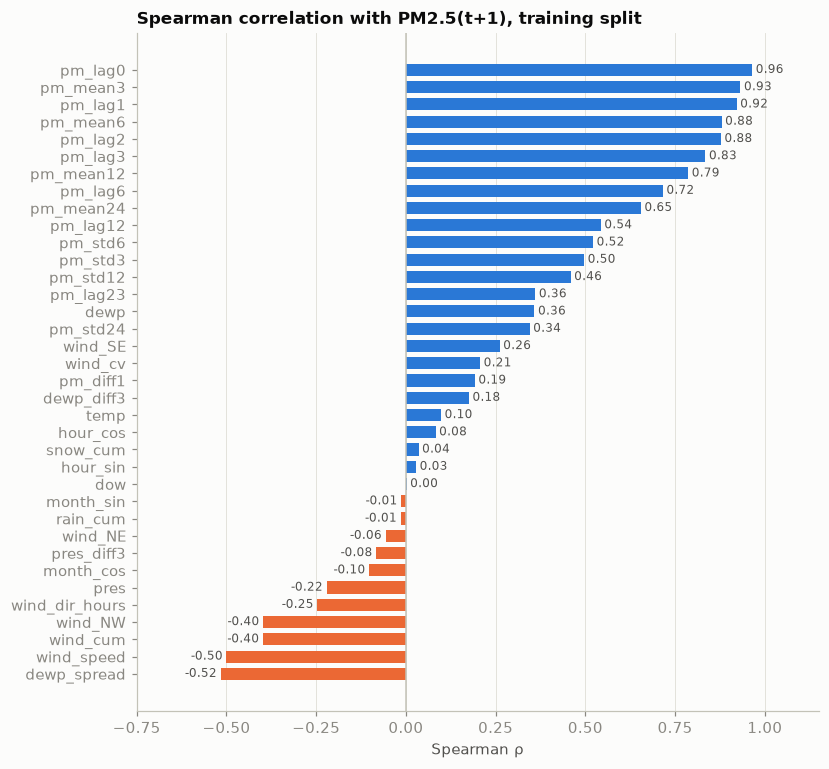

In [9]:
tr = (split == 'train') & mask
const = [c for c in X.columns if X.loc[tr, c].nunique() <= 1]
print('constant on scored training rows (excluded from this plot):', const)
rho = X.loc[tr, X.columns.difference(const)].corrwith(y[tr], method='spearman').sort_values()
fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(rho.index, rho.values, color=[ps.SERIES[0] if v >= 0 else ps.SERIES[1] for v in rho.values], height=0.7)
ax.axvline(0, color=ps.AXIS, linewidth=1)
for i, v in enumerate(rho.values):
    ax.text(v + (0.01 if v >= 0 else -0.01), i, f'{v:.2f}', va='center', ha='left' if v >= 0 else 'right', fontsize=8, color=ps.INK_2)
ax.set(title='Spearman correlation with PM2.5(t+1), training split', xlabel='Spearman ρ', xlim=(-0.75, 1.15))
ax.grid(axis='y', visible=False)
ps.save(fig, 'features_01_train_correlation'); plt.show()

## 7. Summary
- 37 features: 17 PM2.5-history, 15 weather/wind, 5 calendar.
- All features at *t* are unchanged when every later row is randomised (30 cut points), so no future information is used.
- 200 random spot checks confirm that lags, rolling means, calendar fields and the target line up with the raw data.
- The wind decoding is exact: re-accumulating `wind_speed` reproduces `wind_cum`.
- PM2.5-history features keep NaN after gaps (handled natively by XGBoost); weather and calendar features are complete.
- `pm_hours_since_obs` is always 0 on the common eval set (which requires pm(t)). It only varies on training rows that follow a gap (training uses every row with an observed target), so it matters for training, not for the scored comparison.